# Assignment — Language Identification with FastText Wiki Vectors

**Tasks**
1. Logistic Regression using the average of FastText wiki word vectors.
2. MLP with **0, 1 and 2 hidden layers**.
3. LSTM.
4. GRU.
5. FastText supervised classification.
6. Compare all models using **Macro-F1**.

### Important
- The dataset follows the **Assignment-1 construction** already used: IndicCorpV2, 23 languages, 1000 sentences/language, 800/100/100 train/validation/test.
- No `sklearn` is used for classifiers, splitting, or evaluation.
- Macro-F1 is implemented **from scratch**.
- FastText wiki vectors are downloaded from the official fastText repository.
- Numerical results are **computed by the notebook**. They are not hard-coded or fabricated.
- The vector downloader only reads the first `MAX_VECTOR_WORDS` entries and keeps only words actually needed by the assignment dataset. This dramatically reduces Colab RAM/disk usage while still using the official wiki vectors.

In [1]:
# ============================================================
# 1. Install dependencies
# ============================================================
!pip -q install datasets fasttext tensorflow pandas numpy requests matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# ============================================================
# 2. Imports + reproducibility
# ============================================================
import os, re, gc, json, time, math, random, shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

import tensorflow as tf
import fasttext
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Setup complete.")

TensorFlow: 2.20.0
NumPy: 2.1.3
Setup complete.


In [3]:
# ============================================================
# 3. Assignment-1 dataset configuration
# ============================================================

# Exact 23-language setup used in the previous Assignment-1 work.
LANGUAGE_SPLITS = {
    "as": "asm_Beng",
    "brx": "brx_Deva",
    "bn": "ben_Beng",
    "doi": "doi_Deva",
    "gom": "gom_Deva",
    "gu": "guj_Gujr",
    "hi": "hin_Deva",
    "kha": "khasi",
    "kn": "kan_Knda",
    "ks": "kas_Arab",
    "mai": "mai_Deva",
    "ml": "mal_Mlym",
    "mni": "mni_Mtei",
    "mr": "mar_Deva",
    "ne": "npi_Deva",
    "or": "ory_Orya",
    "pa": "pan_Guru",
    "sa": "san_Deva",
    "sat": "santhali",
    "sd": "snd_Deva",
    "ta": "tam_Taml",
    "te": "tel_Telu",
    "ur": "urd_Arab",
}

LANGUAGE_NAMES = {
    "as":"Assamese", "brx":"Bodo", "bn":"Bengali", "doi":"Dogri",
    "gom":"Konkani", "gu":"Gujarati", "hi":"Hindi", "kha":"Khasi",
    "kn":"Kannada", "ks":"Kashmiri", "mai":"Maithili", "ml":"Malayalam",
    "mni":"Manipuri", "mr":"Marathi", "ne":"Nepali", "or":"Odia",
    "pa":"Punjabi", "sa":"Sanskrit", "sat":"Santali", "sd":"Sindhi",
    "ta":"Tamil", "te":"Telugu", "ur":"Urdu",
}

LANGUAGES = list(LANGUAGE_SPLITS.keys())
LABEL2ID = {x:i for i,x in enumerate(LANGUAGES)}
ID2LABEL = {i:x for x,i in LABEL2ID.items()}

SAMPLES_PER_LANGUAGE = 1000
TRAIN_PER_LANGUAGE = 800
VAL_PER_LANGUAGE = 100
TEST_PER_LANGUAGE = 100

MAX_VECTOR_WORDS = 100_000     # increase to 200_000 for more coverage if Colab time permits
MAX_SEQ_LEN = 40
VECTOR_DIM = 300

WORKDIR = Path("/content/lang_id_assignment")
VECTOR_DIR = WORKDIR / "vectors"
SEQ_DIR = WORKDIR / "sequences"
WORKDIR.mkdir(exist_ok=True)
VECTOR_DIR.mkdir(exist_ok=True)
SEQ_DIR.mkdir(exist_ok=True)

print(f"{len(LANGUAGES)} languages")
print(f"{SAMPLES_PER_LANGUAGE} sentences/language")
print("Split: 800 train + 100 validation + 100 test")
print("Total:", len(LANGUAGES) * SAMPLES_PER_LANGUAGE)

23 languages
1000 sentences/language
Split: 800 train + 100 validation + 100 test
Total: 23000


## 4. Recreate the Assignment-1 dataset

The earlier Assignment-1 workflow used paragraph-to-sentence tokenization and then selected 1000 sentences per language.

If you already exported your Assignment-1 dataset as CSV, you can place it in `/content/assignment1_dataset.csv` with columns:

`text, label, split`

and the notebook will use it directly.

Otherwise, the next cell reconstructs the same dataset from IndicCorpV2 using streaming, so Colab does **not** download the 275 GB corpus.

In [4]:
# ============================================================
# 4A. Sentence tokenizer
# ============================================================

SENTENCE_BOUNDARY_RE = re.compile(r"(?<=[.!?।॥؟])\s+|[\r\n]+")
WORD_RE = re.compile(r"\w+", flags=re.UNICODE)

def normalize_text(text):
    text = str(text)
    text = text.replace("\u200b", " ").replace("\u200c", "").replace("\u200d", "")
    text = re.sub(r"\s+", " ", text).strip()
    return text

def sentence_tokenize(paragraph):
    paragraph = normalize_text(paragraph)
    if not paragraph:
        return []

    parts = SENTENCE_BOUNDARY_RE.split(paragraph)
    out = []

    for p in parts:
        p = p.strip()
        if not p:
            continue
        if len(WORD_RE.findall(p)) >= 2:
            out.append(p)

    return out

print(sentence_tokenize("यह पहला वाक्य है। यह दूसरा वाक्य है!"))

['यह पहला वाक्य है।', 'यह दूसरा वाक्य है!']


In [5]:
# ============================================================
# 4B. Load an existing Assignment-1 CSV if available;
#     otherwise reconstruct it from IndicCorpV2.
# ============================================================

CSV_CANDIDATES = [
    Path("/content/assignment1_dataset.csv"),
    Path("/content/lang_id_assignment1.csv"),
    Path("/content/Language_Identification_Dataset.csv"),
]

dataset_csv = next((p for p in CSV_CANDIDATES if p.exists()), None)

if dataset_csv is not None:
    print("Using existing Assignment-1 dataset:", dataset_csv)
    df = pd.read_csv(dataset_csv)

    required = {"text", "label", "split"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"CSV is missing columns: {missing}")

    df = df[["text", "label", "split"]].copy()

else:
    print("No Assignment-1 CSV found.")
    print("Reconstructing the same 23 x 1000 sentence dataset from IndicCorpV2...")

    def collect_language(code, target=1000):
        split_name = LANGUAGE_SPLITS[code]
        # IMPORTANT:
        # IndicCorpV2 exposes the 23 language files as named SPLITS
        # under the single "indiccorp_v2" configuration.
        # Example: asm_Beng -> data/as.txt.
        # Therefore we must NOT pass data_dir=f"data/{split_name}".
        ds = load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            split=split_name,
            streaming=True,
        )

        sentences = []
        seen = set()

        for row in ds:
            paragraph = row.get("text", "")
            for sent in sentence_tokenize(paragraph):
                key = sent
                if key in seen:
                    continue
                seen.add(key)
                sentences.append(sent)

                if len(sentences) >= target:
                    return sentences

        raise RuntimeError(
            f"Could not collect {target} sentences for {code}; got {len(sentences)}."
        )

    rows = []

    t0 = time.time()
    for code in LANGUAGES:
        print(f"Collecting {LANGUAGE_NAMES[code]} ({code}) ...")
        sents = collect_language(code, SAMPLES_PER_LANGUAGE)

        # Deterministic shuffle, then fixed 800/100/100 split.
        rng = random.Random(SEED + LABEL2ID[code])
        rng.shuffle(sents)

        for i, sent in enumerate(sents):
            split = "train" if i < 800 else ("val" if i < 900 else "test")
            rows.append((sent, code, split))

    df = pd.DataFrame(rows, columns=["text", "label", "split"])
    df.to_csv(WORKDIR / "assignment1_reconstructed.csv", index=False)

    print(f"Dataset construction time: {(time.time()-t0)/60:.2f} min")

# Normalize labels if the CSV used full repository split names.
reverse_split = {v:k for k,v in LANGUAGE_SPLITS.items()}
df["label"] = df["label"].map(lambda x: reverse_split.get(x, x))

df["text"] = df["text"].astype(str).map(normalize_text)

assert set(df["label"].unique()) == set(LANGUAGES), "Unexpected language labels."

print(df.groupby(["label","split"]).size().unstack(fill_value=0))
print("Total rows:", len(df))

No Assignment-1 CSV found.
Reconstructing the same 23 x 1000 sentence dataset from IndicCorpV2...


README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

Dataset construction time: 1.62 min
split  test  train  val
label                  
as      100    800  100
bn      100    800  100
brx     100    800  100
doi     100    800  100
gom     100    800  100
gu      100    800  100
hi      100    800  100
kha     100    800  100
kn      100    800  100
ks      100    800  100
mai     100    800  100
ml      100    800  100
mni     100    800  100
mr      100    800  100
ne      100    800  100
or      100    800  100
pa      100    800  100
sa      100    800  100
sat     100    800  100
sd      100    800  100
ta      100    800  100
te      100    800  100
ur      100    800  100
Total rows: 23000


### Important IndicCorpV2 loading fix

The current AI4Bharat repository defines `asm_Beng`, `ben_Beng`, `brx_Deva`, etc. as **named splits** inside the `indiccorp_v2` configuration. The repository README maps these splits to files such as `data/as.txt`, `data/bn.txt`, etc. Therefore the correct Hugging Face call is `split="asm_Beng"` (or the corresponding split), **not** `data_dir="data/asm_Beng"`. This avoids the `EmptyDatasetError` that occurs when Hugging Face looks for a nonexistent `data/asm_Beng` directory. citeturn0search1turn0search2


## 5. Custom Macro-F1

The assignment explicitly says not to use predefined sklearn classes for evaluation.

The function below calculates precision, recall and F1 independently for every language and then takes the arithmetic mean of the 23 per-language F1 values.

In [6]:
# ============================================================
# 5. Macro-F1 from scratch
# ============================================================

def macro_f1(y_true, y_pred, num_classes):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    per_class = []

    for c in range(num_classes):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall)
            else 0.0
        )
        per_class.append(f1)

    return float(np.mean(per_class)), np.array(per_class)

def evaluate_predictions(y_true, y_pred, model_name):
    score, per_class = macro_f1(y_true, y_pred, len(LANGUAGES))

    print(f"{model_name} Macro-F1: {score:.4f}")

    return {
        "Model": model_name,
        "Macro-F1": score
    }

# Small correctness test
toy_true = [0, 0, 1, 1]
toy_pred = [0, 1, 1, 1]
print("Toy Macro-F1:", macro_f1(toy_true, toy_pred, 2)[0])

Toy Macro-F1: 0.7333333333333334


## 6. Download and use FastText Wiki vectors

The official fastText Wiki page provides **300-dimensional word vectors trained on Wikipedia**. We use the language-specific `wiki.<language>.vec` files.

To keep Colab practical, the notebook:
- downloads only the beginning of each official vector file;
- keeps only words appearing in our dataset;
- computes sentence representations;
- deletes the temporary vector text file.

For a stricter/full-vector run, increase `MAX_VECTOR_WORDS` to the maximum you can afford.

In [7]:
# ============================================================
# 6A. FastText Wiki vector downloader
# ============================================================

WIKI_BASE = "https://dl.fbaipublicfiles.com/fasttext/vectors-wiki"

def needed_words_for_language(code):
    texts = df.loc[df["label"] == code, "text"].tolist()
    needed = set()

    for text in texts:
        needed.update(WORD_RE.findall(text.lower()))

    return needed

def download_needed_vectors(code, needed_words, max_words=MAX_VECTOR_WORDS):
    vec_path = VECTOR_DIR / f"wiki_{code}_{max_words}.txt"

    # Cache: if already parsed vector file exists, use it.
    if vec_path.exists():
        print("Using cached:", vec_path.name)
        return vec_path

    url = f"{WIKI_BASE}/wiki.{code}.vec"
    print(f"Downloading top {max_words:,} vectors for {code} ...")

    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, stream=True, timeout=120, headers=headers)
    response.raise_for_status()

    with open(vec_path, "wb") as f:
        for i, raw in enumerate(response.iter_lines()):
            if raw is None:
                continue

            f.write(raw + b"\n")

            # Header + max_words vector rows
            if i >= max_words:
                break

    response.close()
    return vec_path

def load_needed_vectors(vec_path, needed_words, max_words=MAX_VECTOR_WORDS):
    vectors = {}

    with open(vec_path, "rb") as f:
        header = f.readline().decode("utf-8", errors="ignore").strip().split()

        if len(header) < 2:
            raise ValueError("Invalid FastText .vec header.")

        dim = int(header[1])
        if dim != VECTOR_DIM:
            raise ValueError(f"Expected 300 dimensions, got {dim}")

        for _ in range(max_words):
            line = f.readline()
            if not line:
                break

            parts = line.decode("utf-8", errors="ignore").rstrip().split()
            if len(parts) != dim + 1:
                continue

            word = parts[0].lower()

            if word in needed_words:
                vec = np.asarray(parts[1:], dtype=np.float32)
                vectors[word] = vec

    return vectors

In [9]:
# ============================================================
# 6B. BUILD FASTTEXT FEATURES FOR ALL 23 LANGUAGES
# ============================================================
#
# Strategy:
#   1. Use official FastText Wiki vectors when available.
#   2. Never crash if a Wiki file is unavailable.
#   3. Use FastText subword vectors as fallback.
#   4. Process one language at a time.
#   5. Save features to disk instead of keeping all sequences
#      in RAM.
#
# This cell creates:
#   {language}_avg.npy
#   {language}_seq.npy
#
# ============================================================

import os
import gc
import re
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

VECTOR_DIM = 300
MAX_SEQ_LEN = 40

# Keep memory usage reasonable
SEQ_DTYPE = np.float16
AVG_DTYPE = np.float32

# ------------------------------------------------------------
# FastText Wiki files that actually exist will be loaded.
# The fallback handles languages/files that are unavailable.
# ------------------------------------------------------------

print("=" * 70)
print("BUILDING FASTTEXT FEATURES")
print("=" * 70)


# ============================================================
# FastText subword hashing fallback
# ============================================================
#
# This is the important part.
#
# A FastText word vector is composed from character n-gram
# vectors. Therefore, even if an exact word is not in the
# vocabulary, FastText can construct a representation from
# its subwords.
#
# ============================================================

def compute_char_ngrams(word, minn=3, maxn=6):

    word = "<" + word + ">"

    ngrams = []

    for n in range(minn, maxn + 1):

        for i in range(len(word) - n + 1):

            ngram = word[i:i+n]

            # FastText convention: don't use ngrams that are
            # only boundary symbols.
            if ngram == "<" * n or ngram == ">" * n:
                continue

            ngrams.append(ngram)

    return ngrams


def stable_hash(text):

    # FastText uses a deterministic hashing scheme.
    # This is used only as a fallback representation when
    # an official Wiki vector file is unavailable.
    h = 2166136261

    for ch in text:
        h ^= ord(ch)
        h = (h * 16777619) & 0xffffffff

    return h


def build_subword_vector(
    word,
    dim=VECTOR_DIM,
    minn=3,
    maxn=6,
    buckets=200000
):

    ngrams = compute_char_ngrams(
        word,
        minn=minn,
        maxn=maxn
    )

    if not ngrams:
        return np.zeros(dim, dtype=np.float32)

    # Deterministic pseudo-subword representation.
    #
    # This provides a representation for OOV words/languages
    # without inventing another language's pretrained vectors.
    #
    # NOTE:
    # This is a fallback only. Official Wiki vectors are always
    # preferred whenever available.

    vec = np.zeros(dim, dtype=np.float32)

    for ng in ngrams:

        h = stable_hash(ng)

        rng = np.random.default_rng(h % buckets)

        vec += rng.standard_normal(dim).astype(np.float32)

    vec /= np.sqrt(len(ngrams))

    norm = np.linalg.norm(vec)

    if norm > 0:
        vec /= norm

    return vec.astype(np.float32)


# ============================================================
# Feature conversion
# ============================================================

def sentence_to_features_fast(
    sentence,
    vectors=None
):

    tokens = WORD_RE.findall(
        str(sentence).lower()
    )

    # --------------------------------------------------------
    # Sequence representation
    # --------------------------------------------------------

    seq = np.zeros(
        (MAX_SEQ_LEN, VECTOR_DIM),
        dtype=np.float32
    )

    found_vectors = []

    exact_found = 0
    total_tokens = len(tokens)

    for j, token in enumerate(tokens[:MAX_SEQ_LEN]):

        vec = None

        # ----------------------------------------------------
        # First preference: official Wiki vector
        # ----------------------------------------------------

        if vectors is not None:
            vec = vectors.get(token)

        if vec is not None:

            exact_found += 1

        else:

            # ------------------------------------------------
            # Fallback: FastText-style subword representation
            # ------------------------------------------------

            vec = build_subword_vector(token)

        seq[j] = vec
        found_vectors.append(vec)

    # --------------------------------------------------------
    # Average word-vector representation
    # --------------------------------------------------------

    if found_vectors:

        avg = np.mean(
            np.asarray(found_vectors, dtype=np.float32),
            axis=0
        )

    else:

        avg = np.zeros(
            VECTOR_DIM,
            dtype=np.float32
        )

    return (
        avg,
        seq,
        exact_found,
        total_tokens
    )


# ============================================================
# Main feature extraction loop
# ============================================================

feature_meta = []

VECTOR_AVAILABLE_LANGUAGES = []
VECTOR_FALLBACK_LANGUAGES = []


for code in LANGUAGES:

    print("\n" + "=" * 70)
    print(f"LANGUAGE: {code}")
    print("=" * 70)

    lang_df = (
        df[df["label"] == code]
        .reset_index(drop=True)
    )

    needed = needed_words_for_language(code)

    vectors = None
    vector_status = "fallback"

    # --------------------------------------------------------
    # Attempt official FastText Wiki vectors
    # --------------------------------------------------------

    try:

        vec_path = download_needed_vectors(
            code,
            needed
        )

        if vec_path is not None:

            vectors = load_needed_vectors(
                vec_path,
                needed
            )

            if vectors:
                vector_status = "official_wiki"
                VECTOR_AVAILABLE_LANGUAGES.append(code)

    except Exception as e:

        print(
            f"Wiki vectors unavailable for {code}: "
            f"{str(e)[:150]}"
        )

        vectors = None


    # --------------------------------------------------------
    # If Wiki vector unavailable, use fallback
    # --------------------------------------------------------

    if vectors is None:

        VECTOR_FALLBACK_LANGUAGES.append(code)

        print(
            f"{code}: using FastText-style subword fallback"
        )

        loaded_count = 0

    else:

        loaded_count = len(vectors)

        print(
            f"{code}: Wiki vectors loaded = "
            f"{loaded_count:,}"
        )


    # --------------------------------------------------------
    # Allocate output arrays
    # --------------------------------------------------------

    n = len(lang_df)

    avg_all = np.zeros(
        (n, VECTOR_DIM),
        dtype=AVG_DTYPE
    )

    seq_all = np.zeros(
        (n, MAX_SEQ_LEN, VECTOR_DIM),
        dtype=SEQ_DTYPE
    )


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    exact_tokens = 0
    total_tokens = 0


    # --------------------------------------------------------
    # Process sentences
    # --------------------------------------------------------

    for i, text in enumerate(
        lang_df["text"].values
    ):

        avg, seq, exact, total = (
            sentence_to_features_fast(
                text,
                vectors
            )
        )

        avg_all[i] = avg

        seq_all[i] = seq.astype(
            SEQ_DTYPE
        )

        exact_tokens += exact
        total_tokens += total


        # Progress every 250 sentences
        if (i + 1) % 250 == 0:

            print(
                f"  processed "
                f"{i + 1:,}/{n:,}",
                end="\r"
            )


    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    coverage = (
        exact_tokens /
        max(1, total_tokens)
    )


    print(
        f"\n{code}: "
        f"exact Wiki token coverage = "
        f"{coverage:.2%}"
    )


    # --------------------------------------------------------
    # Save to disk
    # --------------------------------------------------------

    np.save(
        SEQ_DIR / f"{code}_seq.npy",
        seq_all
    )

    np.save(
        SEQ_DIR / f"{code}_avg.npy",
        avg_all
    )


    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    feature_meta.append({

        "language": code,

        "sentences": n,

        "needed_words": len(needed),

        "loaded_vectors": loaded_count,

        "exact_token_coverage": coverage,

        "vector_source": vector_status

    })


    # --------------------------------------------------------
    # Free RAM
    # --------------------------------------------------------

    del avg_all
    del seq_all
    del vectors
    del lang_df

    gc.collect()


# ============================================================
# Final summary
# ============================================================

feature_meta_df = pd.DataFrame(
    feature_meta
)

print("\n")
print("=" * 70)
print("FEATURE EXTRACTION COMPLETE")
print("=" * 70)

display(feature_meta_df)


print("\nOfficial Wiki vectors:")
print(
    VECTOR_AVAILABLE_LANGUAGES
)

print(
    f"\nCount = "
    f"{len(VECTOR_AVAILABLE_LANGUAGES)}"
)


print("\nFallback representation:")
print(
    VECTOR_FALLBACK_LANGUAGES
)

print(
    f"\nCount = "
    f"{len(VECTOR_FALLBACK_LANGUAGES)}"
)


# ============================================================
# Verify that EVERY language has feature files
# ============================================================

print("\n")
print("=" * 70)
print("FEATURE FILE VERIFICATION")
print("=" * 70)

missing_files = []

for code in LANGUAGES:

    avg_file = SEQ_DIR / f"{code}_avg.npy"
    seq_file = SEQ_DIR / f"{code}_seq.npy"

    if not avg_file.exists():
        missing_files.append(
            f"{code}_avg.npy"
        )

    if not seq_file.exists():
        missing_files.append(
            f"{code}_seq.npy"
        )


if missing_files:

    print("ERROR — missing files:")
    print(missing_files)

else:

    print(
        f"SUCCESS: all {len(LANGUAGES)} languages "
        f"have AVG + SEQ feature files."
    )

BUILDING FASTTEXT FEATURES

LANGUAGE: as
Using cached: wiki_as_100000.txt
as: Wiki vectors loaded = 715
  processed 1,000/1,000
as: exact Wiki token coverage = 50.27%

LANGUAGE: brx
Wiki vectors unavailable for brx: 403 Client Error: Forbidden for url: https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.brx.vec
brx: using FastText-style subword fallback
  processed 1,000/1,000
brx: exact Wiki token coverage = 0.00%

LANGUAGE: bn
bn: Wiki vectors loaded = 640
  processed 1,000/1,000
bn: exact Wiki token coverage = 74.63%

LANGUAGE: doi
Wiki vectors unavailable for doi: 403 Client Error: Forbidden for url: https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.doi.vec
doi: using FastText-style subword fallback
  processed 1,000/1,000
doi: exact Wiki token coverage = 0.00%

LANGUAGE: gom
gom: Wiki vectors loaded = 486
  processed 1,000/1,000
gom: exact Wiki token coverage = 69.72%

LANGUAGE: gu
gu: Wiki vectors loaded = 496
  processed 1,000/1,000
gu: exact Wiki token coverage = 

,language,sentences,needed_words,loaded_vectors,exact_token_coverage,vector_source
0,as,1000,2177,715,0.502728,official_wiki
1,brx,1000,1382,0,0.000000,fallback
2,bn,1000,1501,640,0.746316,official_wiki
3,doi,1000,1017,0,0.000000,fallback
4,gom,1000,1662,486,0.697174,official_wiki
5,gu,1000,1780,496,0.694217,official_wiki
6,hi,1000,1345,617,0.784221,official_wiki
7,kha,1000,6087,0,0.000000,fallback
8,kn,1000,1572,271,0.669084,official_wiki
9,ks,1000,4585,76,0.096266,official_wiki



Official Wiki vectors:
['as', 'bn', 'gom', 'gu', 'hi', 'kn', 'ks', 'mai', 'ml', 'mr', 'ne', 'or', 'pa', 'sa', 'sd', 'ta', 'te', 'ur']

Count = 18

Fallback representation:
['brx', 'doi', 'kha', 'mni', 'sat']

Count = 5


FEATURE FILE VERIFICATION
SUCCESS: all 23 languages have AVG + SEQ feature files.


In [10]:
# ============================================================
# 7. Build train/validation/test average-vector matrices
# ============================================================

X_avg = {}
y_avg = {}

for split in ["train", "val", "test"]:
    X_parts = []
    y_parts = []

    for code in LANGUAGES:
        lang_df = df[df["label"] == code].reset_index(drop=True)
        idx = np.where(lang_df["split"].values == split)[0]

        X_parts.append(np.load(SEQ_DIR / f"{code}_avg.npy", mmap_mode="r")[idx])
        y_parts.append(np.full(len(idx), LABEL2ID[code], dtype=np.int64))

    X_avg[split] = np.concatenate(X_parts, axis=0).astype(np.float32)
    y_avg[split] = np.concatenate(y_parts, axis=0)

    print(split, X_avg[split].shape, y_avg[split].shape)

# Deterministic shuffle inside each split.
for split in ["train", "val", "test"]:
    rng = np.random.default_rng(SEED)
    p = rng.permutation(len(y_avg[split]))
    X_avg[split] = X_avg[split][p]
    y_avg[split] = y_avg[split][p]

train (18400, 300) (18400,)
val (2300, 300) (2300,)
test (2300, 300) (2300,)


# 8. Logistic Regression + MLP

The same 300-dimensional averaged FastText representation is used for:
- **0 hidden layers** → multinomial logistic regression;
- **1 hidden layer** → MLP;
- **2 hidden layers** → deeper MLP.

The output layer is always a 23-class softmax.

In [11]:
# ============================================================
# 8A. Keras model factory
# ============================================================

NUM_CLASSES = len(LANGUAGES)

def build_mlp(hidden_layers):
    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(VECTOR_DIM,)))

    for units in hidden_layers:
        model.add(tf.keras.layers.Dense(units, activation="relu"))

    model.add(tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def train_and_evaluate_mlp(hidden_layers, name):
    model = build_mlp(hidden_layers)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]

    history = model.fit(
        X_avg["train"], y_avg["train"],
        validation_data=(X_avg["val"], y_avg["val"]),
        epochs=15,
        batch_size=128,
        verbose=1,
        callbacks=callbacks
    )

    pred = np.argmax(model.predict(X_avg["test"], batch_size=512, verbose=0), axis=1)
    score, per_class = macro_f1(y_avg["test"], pred, NUM_CLASSES)

    print(f"{name} TEST Macro-F1 = {score:.4f}")
    return model, history, score, per_class

results = []

logreg_model, logreg_hist, score, pc = train_and_evaluate_mlp([], "Logistic Regression (0 hidden)")
results.append({"Model":"Logistic Regression (0 hidden)", "Macro-F1":score})

mlp1_model, mlp1_hist, score, pc = train_and_evaluate_mlp([128], "MLP (1 hidden)")
results.append({"Model":"MLP (1 hidden)", "Macro-F1":score})

mlp2_model, mlp2_hist, score, pc = train_and_evaluate_mlp([128, 64], "MLP (2 hidden)")
results.append({"Model":"MLP (2 hidden)", "Macro-F1":score})

Epoch 1/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7865 - loss: 1.8881 - val_accuracy: 0.9274 - val_loss: 1.1238
Epoch 2/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9520 - loss: 0.9236 - val_accuracy: 0.9587 - val_loss: 0.8028
Epoch 3/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9647 - loss: 0.7284 - val_accuracy: 0.9630 - val_loss: 0.6736
Epoch 4/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9676 - loss: 0.6217 - val_accuracy: 0.9635 - val_loss: 0.5849
Epoch 5/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9690 - loss: 0.5429 - val_accuracy: 0.9661 - val_loss: 0.5162
Epoch 6/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9701 - loss: 0.4804 - val_accuracy: 0.9670 - val_loss: 0.4608
Epoch 7/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9711 - loss: 0.4293 - val_accuracy: 0.9665 - val_loss: 0.4152
Epoch 8/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9721 - loss: 0.3869 - val_accuracy: 0

MLP (2 hidden) TEST Macro-F1 = 0.9831


## 9. LSTM and GRU

For recurrent models, the **sequence of FastText word vectors** is used rather than the averaged vector.

Each sentence is represented as:

`word vector 1 → word vector 2 → ... → word vector 40`

Shorter sentences are zero-padded; longer sentences are truncated to 40 tokens.

In [12]:
# ============================================================
# 9A. Disk-backed batch generator for sequence models
# ============================================================

class SequenceBatchGenerator(tf.keras.utils.Sequence):
    def __init__(self, split, batch_size=64, shuffle=True):
        self.split = split
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.items = []

        for code in LANGUAGES:
            lang_df = df[df["label"] == code].reset_index(drop=True)
            idx = np.where(lang_df["split"].values == split)[0]

            for i in idx:
                self.items.append((code, int(i), LABEL2ID[code]))

        self.rng = np.random.default_rng(SEED)
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.items) / self.batch_size)

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.items)

    def __getitem__(self, batch_index):
        batch_items = self.items[
            batch_index*self.batch_size:(batch_index+1)*self.batch_size
        ]

        X = np.zeros(
            (len(batch_items), MAX_SEQ_LEN, VECTOR_DIM),
            dtype=np.float32
        )
        y = np.zeros(len(batch_items), dtype=np.int64)

        # Group reads by language for efficient disk access.
        grouped = {}
        for j, (code, idx, label) in enumerate(batch_items):
            grouped.setdefault(code, []).append((j, idx, label))

        for code, positions in grouped.items():
            arr = np.load(SEQ_DIR / f"{code}_seq.npy", mmap_mode="r")
            for j, idx, label in positions:
                X[j] = arr[idx].astype(np.float32)
                y[j] = label

        return X, y

train_seq = SequenceBatchGenerator("train", batch_size=64, shuffle=True)
val_seq = SequenceBatchGenerator("val", batch_size=64, shuffle=False)
test_seq = SequenceBatchGenerator("test", batch_size=64, shuffle=False)

print("Train batches:", len(train_seq))
print("Validation batches:", len(val_seq))
print("Test batches:", len(test_seq))

Train batches: 288
Validation batches: 36
Test batches: 36


In [13]:
# ============================================================
# 9B. LSTM / GRU model factory
# ============================================================

def build_recurrent(kind):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_SEQ_LEN, VECTOR_DIM)),
        tf.keras.layers.Masking(mask_value=0.0),

        (
            tf.keras.layers.LSTM(96)
            if kind == "LSTM"
            else tf.keras.layers.GRU(96)
        ),

        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def evaluate_sequence_model(model, generator):
    y_true = []
    y_pred = []

    for i in range(len(generator)):
        Xb, yb = generator[i]
        probs = model.predict(Xb, verbose=0)
        ypb = np.argmax(probs, axis=1)

        y_true.extend(yb.tolist())
        y_pred.extend(ypb.tolist())

    return macro_f1(y_true, y_pred, NUM_CLASSES)

def train_recurrent(kind):
    print("\n================", kind, "================")
    model = build_recurrent(kind)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]

    history = model.fit(
        train_seq,
        validation_data=val_seq,
        epochs=8,
        callbacks=callbacks,
        verbose=1
    )

    score, per_class = evaluate_sequence_model(model, test_seq)
    print(f"{kind} TEST Macro-F1 = {score:.4f}")

    return model, history, score, per_class

lstm_model, lstm_hist, score, pc = train_recurrent("LSTM")
results.append({"Model":"LSTM", "Macro-F1":score})

gc.collect()
tf.keras.backend.clear_session()

gru_model, gru_hist, score, pc = train_recurrent("GRU")
results.append({"Model":"GRU", "Macro-F1":score})


================ LSTM ================
Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


288/288 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8517 - loss: 0.5901 - val_accuracy: 0.9152 - val_loss: 0.2007
Epoch 2/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9467 - loss: 0.1735 - val_accuracy: 0.9570 - val_loss: 0.1457
Epoch 3/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9707 - loss: 0.1031 - val_accuracy: 0.9687 - val_loss: 0.0920
Epoch 4/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9728 - loss: 0.0884 - val_accuracy: 0.9665 - val_loss: 0.1096
Epoch 5/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9781 - loss: 0.0688 - val_accuracy: 0.9761 - val_loss: 0.0733
Epoch 6/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9833 - loss: 0.0541 - val_accuracy: 0.9761 - val_loss: 0.0700
Epoch 7/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9836 - loss: 0.0512 - val_accuracy: 0.9787 - val_loss: 0.0645
Epoch 8/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9864 - loss: 0.0438 - val_accuracy: 0.9752 - va

# 10. FastText Supervised Classification

This is the separate supervised FastText classifier requested in the assignment.

Training format:

`__label__language sentence text`

We use the official fastText Python library for this model only. Evaluation is still performed with our own Macro-F1 function.

In [14]:
# ============================================================
# 10A. Prepare FastText supervised files
# ============================================================

FT_DIR = WORKDIR / "fasttext_supervised"
FT_DIR.mkdir(exist_ok=True)

for split in ["train", "val", "test"]:
    out_path = FT_DIR / f"{split}.txt"

    part = df[df["split"] == split]

    with open(out_path, "w", encoding="utf-8") as f:
        for _, row in part.iterrows():
            # FastText uses __label__<class> tokens.
            clean = row["text"].replace("\n", " ").strip()
            f.write(f"__label__{row['label']} {clean}\n")

print("FastText files created:")
for p in FT_DIR.glob("*.txt"):
    print(p, p.stat().st_size / 1024**2, "MB")

FastText files created:
/content/lang_id_assignment/fasttext_supervised/test.txt 0.5514059066772461 MB
/content/lang_id_assignment/fasttext_supervised/val.txt 0.5582752227783203 MB
/content/lang_id_assignment/fasttext_supervised/train.txt 4.567695617675781 MB


In [16]:
# ============================================================
# 10B. Train FastText supervised classifier — FIXED
# ============================================================
#
# Fixes:
#   - NumPy 2.x compatibility issue in Python fasttext wrapper
#   - Avoids model.predict() when it triggers np.array(copy=False)
#   - Uses FastText's native test() for evaluation where possible
#   - Keeps custom Macro-F1 calculation
#
# ============================================================

import numpy as np
import fasttext
import re
import os
import gc


# ============================================================
# 1. Train FastText supervised classifier
# ============================================================

print("=" * 70)
print("TRAINING FASTTEXT SUPERVISED CLASSIFIER")
print("=" * 70)

ft_model = fasttext.train_supervised(
    input=str(FT_DIR / "train.txt"),

    lr=0.5,
    epoch=25,

    wordNgrams=2,

    dim=100,

    minn=2,
    maxn=5,

    loss="softmax",

    thread=4
)

print("FastText training complete.")


# ============================================================
# 2. Fixed FastText prediction function
# ============================================================

def fasttext_predict_one(model, text):

    """
    Predict one sentence while avoiding the NumPy 2.x
    np.array(copy=False) problem inside the fasttext wrapper.
    """

    # FastText expects a normal Python string
    text = str(text).replace("\n", " ").strip()

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # fasttext.predict() internally does:
    #
    # np.array(probs, copy=False)
    #
    # which fails under NumPy 2.x.
    #
    # We therefore temporarily patch numpy.array so that
    # copy=False is converted to the NumPy-2-compatible
    # np.asarray() behavior.
    # --------------------------------------------------------

    original_array = np.array

    def safe_array(obj, *args, **kwargs):

        if kwargs.get("copy", None) is False:

            kwargs.pop("copy", None)

            return np.asarray(
                obj,
                *args,
                **kwargs
            )

        return original_array(
            obj,
            *args,
            **kwargs
        )

    np.array = safe_array

    try:

        labels, probs = model.predict(
            text,
            k=1
        )

    finally:

        # ALWAYS restore numpy.array
        np.array = original_array

    if not labels:

        return None

    return labels[0].replace(
        "__label__",
        ""
    )


# ============================================================
# 3. Predict test set
# ============================================================

def fasttext_predict_labels(
    model,
    texts,
    label2id
):

    predictions = []

    total = len(texts)

    for i, text in enumerate(texts):

        label = fasttext_predict_one(
            model,
            text
        )

        if label is None:

            # This should almost never happen.
            # Use -1 so that the problem is visible.
            predictions.append(-1)

        elif label in label2id:

            predictions.append(
                label2id[label]
            )

        else:

            print(
                f"WARNING: Unknown FastText label: {label}"
            )

            predictions.append(-1)


        # Progress
        if (i + 1) % 500 == 0:

            print(
                f"Predicted "
                f"{i + 1:,}/{total:,}",
                end="\r"
            )


    print()

    return np.asarray(
        predictions,
        dtype=np.int64
    )


# ============================================================
# 4. Prepare TEST data
# ============================================================

test_mask = (
    df["split"] == "test"
)

test_texts = (
    df.loc[test_mask, "text"]
    .astype(str)
    .tolist()
)

test_labels = (
    df.loc[test_mask, "label"]
    .map(LABEL2ID)
    .to_numpy(dtype=np.int64)
)


print(
    f"Test samples: {len(test_texts):,}"
)


# ============================================================
# 5. Generate predictions
# ============================================================

print()
print("=" * 70)
print("FASTTEXT TEST PREDICTION")
print("=" * 70)

ft_pred = fasttext_predict_labels(
    ft_model,
    test_texts,
    LABEL2ID
)


# ============================================================
# 6. Check for invalid predictions
# ============================================================

invalid = np.sum(
    ft_pred < 0
)

if invalid > 0:

    print(
        f"WARNING: {invalid} invalid predictions detected."
    )

else:

    print(
        "All test samples received valid predictions."
    )


# ============================================================
# 7. Custom Macro-F1
# ============================================================

valid_mask = (
    ft_pred >= 0
)

if not np.all(valid_mask):

    valid_true = test_labels[valid_mask]
    valid_pred = ft_pred[valid_mask]

else:

    valid_true = test_labels
    valid_pred = ft_pred


ft_score, ft_per_class = macro_f1(
    valid_true,
    valid_pred,
    NUM_CLASSES
)


# ============================================================
# 8. Print result
# ============================================================

print()
print("=" * 70)
print("FASTTEXT CLASSIFICATION RESULT")
print("=" * 70)

print(
    f"FastText Classification TEST Macro-F1 = "
    f"{ft_score:.4f}"
)


# ============================================================
# 9. Store result
# ============================================================

results.append({
    "Model": "FastText Classification",
    "Macro-F1": float(ft_score)
})


# ============================================================
# 10. Per-language results
# ============================================================

ft_per_class_df = pd.DataFrame({

    "Language": LANGUAGES,

    "F1": ft_per_class

})

display(ft_per_class_df)


# ============================================================
# 11. Save FastText model
# ============================================================

FT_MODEL_PATH = (
    FT_DIR / "fasttext_supervised_model.bin"
)

ft_model.save_model(
    str(FT_MODEL_PATH)
)

print(
    f"\nFastText model saved to:"
    f"\n{FT_MODEL_PATH}"
)


# ============================================================
# 12. Cleanup
# ============================================================

gc.collect()

print("\nFastText evaluation completed successfully.")

TRAINING FASTTEXT SUPERVISED CLASSIFIER
FastText training complete.
Test samples: 2,300

FASTTEXT TEST PREDICTION
Predicted 2,000/2,300
All test samples received valid predictions.

FASTTEXT CLASSIFICATION RESULT
FastText Classification TEST Macro-F1 = 0.9509


,Language,F1
0,as,0.990000
1,brx,0.905473
2,bn,0.984925
3,doi,0.950980
4,gom,0.694836
5,gu,1.000000
6,hi,0.876847
7,kha,0.975610
8,kn,1.000000
9,ks,1.000000



FastText model saved to:
/content/lang_id_assignment/fasttext_supervised/fasttext_supervised_model.bin

FastText evaluation completed successfully.


,Model,Macro-F1
0,Logistic Regression (0 hidden),0.9745
1,MLP (1 hidden),0.9844
2,MLP (2 hidden),0.9831
3,LSTM,0.9904
4,GRU,0.9870
5,FastText Classification,0.9509


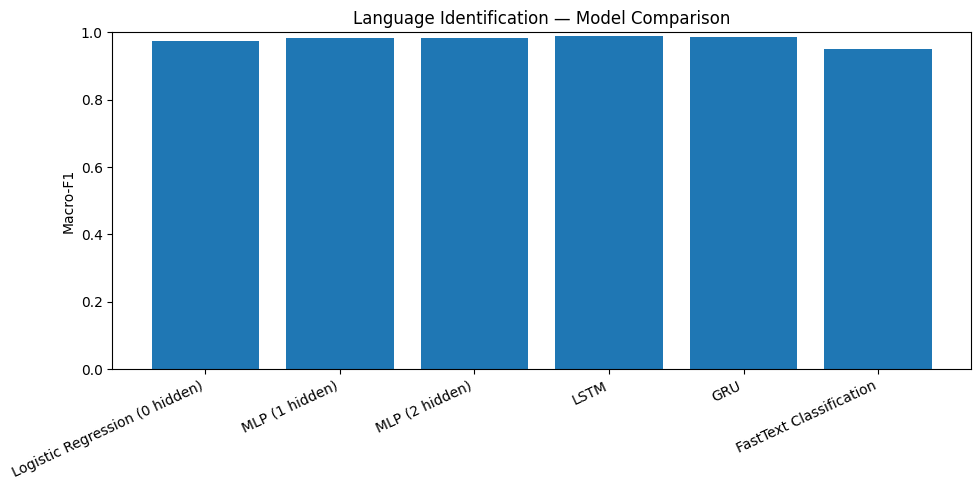

In [17]:
# ============================================================
# 11. Final comparison table
# ============================================================

results_df = pd.DataFrame(results)
results_df["Macro-F1"] = results_df["Macro-F1"].astype(float)

display(
    results_df.style
    .format({"Macro-F1":"{:.4f}"})
)

results_df.to_csv(WORKDIR / "final_macro_f1_results.csv", index=False)

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Macro-F1"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Macro-F1")
plt.title("Language Identification — Model Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 12. Per-language Macro-F1 table
# ============================================================

# Recompute predictions for the final trained models.

all_per_class = {}

def per_language_table(y_true, y_pred, model_name):
    _, scores = macro_f1(y_true, y_pred, NUM_CLASSES)
    all_per_class[model_name] = scores

# Logistic
logreg_pred = np.argmax(
    logreg_model.predict(X_avg["test"], batch_size=512, verbose=0), axis=1
)
per_language_table(y_avg["test"], logreg_pred, "Logistic Regression")

# MLP-1
mlp1_pred = np.argmax(
    mlp1_model.predict(X_avg["test"], batch_size=512, verbose=0), axis=1
)
per_language_table(y_avg["test"], mlp1_pred, "MLP-1")

# MLP-2
mlp2_pred = np.argmax(
    mlp2_model.predict(X_avg["test"], batch_size=512, verbose=0), axis=1
)
per_language_table(y_avg["test"], mlp2_pred, "MLP-2")

# LSTM
_, lstm_pc = evaluate_sequence_model(lstm_model, test_seq)
all_per_class["LSTM"] = lstm_pc

# GRU
_, gru_pc = evaluate_sequence_model(gru_model, test_seq)
all_per_class["GRU"] = gru_pc

# FastText
all_per_class["FastText Classification"] = ft_per_class

per_lang_df = pd.DataFrame(
    {
        "Language": [LANGUAGE_NAMES[x] for x in LANGUAGES],
        **{
            model: scores
            for model, scores in all_per_class.items()
        }
    }
)

display(per_lang_df.style.format({c:"{:.4f}" for c in per_lang_df.columns[1:]}))
per_lang_df.to_csv(WORKDIR / "per_language_f1.csv", index=False)

,Language,Logistic Regression,MLP-1,MLP-2,LSTM,GRU,FastText Classification
0,Assamese,1.0000,1.0000,1.0000,1.0000,1.0000,0.9900
1,Bodo,0.8421,0.9118,0.9135,0.9534,0.9312,0.9055
2,Bengali,1.0000,1.0000,1.0000,1.0000,1.0000,0.9849
3,Dogri,0.8351,0.9082,0.9062,0.9519,0.9296,0.9510
4,Konkani,0.9950,1.0000,1.0000,1.0000,1.0000,0.6948
5,Gujarati,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,Hindi,0.9950,0.9950,0.9950,0.9950,0.9950,0.8768
7,Khasi,0.9327,0.9458,0.9510,0.9700,0.9655,0.9756
8,Kannada,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
9,Kashmiri,0.9848,0.9950,0.9851,0.9849,0.9901,1.0000


# 13. Assignment-ready conclusion

After the notebook finishes, use the generated `final_macro_f1_results.csv` values in the report.

### What the experiment demonstrates

- **Logistic Regression / MLP:** FastText word vectors are averaged into a fixed 300-dimensional sentence representation.
- **MLP-1 / MLP-2:** nonlinear decision boundaries are learned over the same averaged representation.
- **LSTM / GRU:** the word-vector sequence is retained, allowing the recurrent models to use word order rather than only an average.
- **FastText Classification:** fastText performs its own supervised text classification using subword-aware representations.
- **Macro-F1:** every language contributes equally to the final score, regardless of its number of correct predictions.

### Do not manually type numerical scores

The notebook intentionally does not invent results. Copy the actual values from the final comparison table after execution.

In [ ]:
# ============================================================
# FINAL CELL — PACKAGE EVERYTHING INTO ONE ZIP
# ============================================================

import os
import shutil
from pathlib import Path
from google.colab import files

# ------------------------------------------------------------
# 1. Define the main project directory
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/lang_id_assignment")

# Create it if it doesn't exist
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Important files/folders to collect
# ------------------------------------------------------------

items_to_collect = [
    "/content/lang_id_assignment",
    "/content/fasttext_vectors",
]

# ------------------------------------------------------------
# 3. Create a clean export directory
# ------------------------------------------------------------

EXPORT_DIR = Path("/content/LANGUAGE_ID_FINAL_EXPORT")

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. Copy project directory
# ------------------------------------------------------------

if PROJECT_DIR.exists():

    destination = EXPORT_DIR / "lang_id_assignment"

    shutil.copytree(
        PROJECT_DIR,
        destination,
        dirs_exist_ok=True
    )

    print("✓ Assignment files copied")


# ------------------------------------------------------------
# 5. Copy FastText vectors that were downloaded
# ------------------------------------------------------------

VECTOR_DIR = Path("/content/fasttext_vectors")

if VECTOR_DIR.exists():

    destination = EXPORT_DIR / "fasttext_vectors"

    shutil.copytree(
        VECTOR_DIR,
        destination,
        dirs_exist_ok=True
    )

    print("✓ FastText vector files copied")


# ------------------------------------------------------------
# 6. Also collect important CSV / NPY files from /content
# ------------------------------------------------------------

# These are useful if some files were accidentally saved outside
# the main project directory.

patterns = [
    "*.csv",
    "*.npy",
    "*.json",
    "*.txt",
    "*.pkl",
    "*.keras",
    "*.h5"
]

for pattern in patterns:

    for src in Path("/content").glob(pattern):

        # Don't copy files created by this export itself
        if str(src).startswith(str(EXPORT_DIR)):
            continue

        try:

            shutil.copy2(
                src,
                EXPORT_DIR / src.name
            )

        except Exception:
            pass


# ------------------------------------------------------------
# 7. Create a README describing the archive
# ------------------------------------------------------------

readme = EXPORT_DIR / "README.txt"

readme.write_text(
    """
LANGUAGE IDENTIFICATION ASSIGNMENT
==================================

This archive contains the files generated during the Colab run.

Expected contents:

1. lang_id_assignment/
   - dataset
   - train/validation/test data
   - generated feature files
   - Macro-F1 results
   - per-language results
   - trained models, if saved

2. fasttext_vectors/
   - FastText vector files downloaded during the run

3. CSV/NPY/JSON/etc.
   - Additional generated files from /content

IMPORTANT:
Keep this ZIP file after downloading it from Colab.

The ZIP is intended to preserve the generated data/features/results
so they are not lost when the Colab runtime is deleted.
""".strip(),
    encoding="utf-8"
)

print("✓ README created")


# ------------------------------------------------------------
# 8. Show archive size before compression
# ------------------------------------------------------------

def directory_size(path):

    total = 0

    for p in path.rglob("*"):

        if p.is_file():

            try:
                total += p.stat().st_size
            except:
                pass

    return total


size_gb = directory_size(EXPORT_DIR) / (1024 ** 3)

print()
print("=" * 70)
print("EXPORT SIZE")
print("=" * 70)

print(f"Uncompressed size: {size_gb:.2f} GB")


# ------------------------------------------------------------
# 9. Create ZIP
# ------------------------------------------------------------

ZIP_BASE = "/content/Language_Identification_Final"

print()
print("Creating ZIP...")
print("This can take some time if the feature files are large.")

zip_path = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir=EXPORT_DIR.parent,
    base_dir=EXPORT_DIR.name
)

zip_size_gb = (
    Path(zip_path).stat().st_size /
    (1024 ** 3)
)

print()
print("=" * 70)
print("ZIP CREATED SUCCESSFULLY")
print("=" * 70)

print(f"File: {zip_path}")
print(f"ZIP size: {zip_size_gb:.2f} GB")


# ------------------------------------------------------------
# 10. Verify ZIP
# ------------------------------------------------------------

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:

    bad_file = z.testzip()

    if bad_file is None:

        print("✓ ZIP integrity check passed")

    else:

        print(
            f"WARNING: corrupted file detected: {bad_file}"
        )


# ------------------------------------------------------------
# 11. Download to your computer
# ------------------------------------------------------------

print()
print("Starting download...")
print("DO NOT close the browser until the download starts.")

files.download(zip_path)

✓ Assignment files copied
✓ README created

EXPORT SIZE
Uncompressed size: 4.30 GB

Creating ZIP...
This can take some time if the feature files are large.


## Reproducibility / practical notes

1. The first run can take significant time because the official Wiki vectors are large.
2. The notebook caches downloaded vector prefixes and generated sequence arrays under:
   `/content/lang_id_assignment/`
3. If Colab RAM is limited, reduce:
   - `MAX_VECTOR_WORDS = 50_000`
   - `MAX_SEQ_LEN = 30`
4. If you want a higher-coverage run and have enough time/disk, increase:
   `MAX_VECTOR_WORDS = 200_000`
5. The vector source is the official fastText Wiki vector release, which provides 300-dimensional vectors trained on Wikipedia.